In [31]:
import pandas as pd
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler


import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

In [32]:
def print_line(num):
    print('=' * num)
    
def print_txt(text, num=50):
    print_line(num)
    print(text)
    print_line(num)

In [33]:
SPLIT_DIR = Path('../data/split/')

train_df = pd.read_csv(SPLIT_DIR / 'train.csv')
test_df = pd.read_csv(SPLIT_DIR / 'test.csv')

In [34]:
# Separate features and target
X_train = train_df.drop(columns=['Datetime', 'PJME_MW'])
y_train = train_df['PJME_MW']

X_test = test_df.drop(columns=['Datetime', 'PJME_MW'])
y_test = test_df['PJME_MW']


In [35]:
print_txt('Verefy the shape of train and test sets')
print(f'Training set   :{X_train.shape, y_train.shape}')
print(f'Testing set    :{X_test.shape, y_test.shape}')

Verefy the shape of train and test sets
Training set   :((116179, 8), (116179,))
Testing set    :((29045, 8), (29045,))


In [36]:
print_txt('Build Linear Regression Pipeline')

model = Pipeline([
                 ('scaler', StandardScaler()),
                 ('regressor', LinearRegression())
                 ])

display(model)

Build Linear Regression Pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None


In [37]:
print_txt('Train Linear Regression')

model.fit(X_train, y_train)

print('Done')

Train Linear Regression
Done


In [38]:
print_txt('Generate predictions')

y_pred = model.predict(X_test)

print(f'first 10 predictions : {y_pred[:10]}')

Generate predictions
first 10 predictions : [32015.74735488 32051.63311661 31182.88345966 29729.98612206
 25074.59429069 23980.77792354 23357.76653857 23070.56781586
 23075.78222118 23457.66454592]


In [39]:
print_txt('Model Evaluation')

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'R²   : {r2:.4f}')
print(f'MAPE : {mape:.2f}%')

Model Evaluation
MAE  : 1837.41
RMSE : 2448.84
R²   : 0.8577
MAPE : 5.82%


In [40]:
print_txt('Evaluate lag_24 baseline')

y_baseline = test_df['lag_24']

baseline_mae = mean_absolute_error(y_test, y_baseline)

baseline_rmse = mean_squared_error(y_test, y_baseline) ** 0.5
baseline_r2 = r2_score(y_test, y_baseline)
baseline_mape = mean_absolute_percentage_error(y_test, y_baseline) * 100

print(f'MAE  : {baseline_mae:.2f}')
print(f'RMSE : {baseline_rmse:.2f}')
print(f'R²   : {baseline_r2:.4f}')
print(f'MAPE : {baseline_mape:.2f}%')

Evaluate lag_24 baseline
MAE  : 2184.27
RMSE : 3009.02
R²   : 0.7851
MAPE : 6.93%


In [41]:
results = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R²', 'MAPE'],
    'Linear Regression': [mae, rmse, r2, mape],
    'lag_24 Baseline': [baseline_mae, baseline_rmse, baseline_r2, baseline_mape ]
        })

display(results.round(2))

,Metric,Linear Regression,lag_24 Baseline
0,MAE,1837.41,2184.27
1,RMSE,2448.84,3009.02
2,R²,0.86,0.79
3,MAPE,5.82,6.93


Actual vs Predicted Consumption


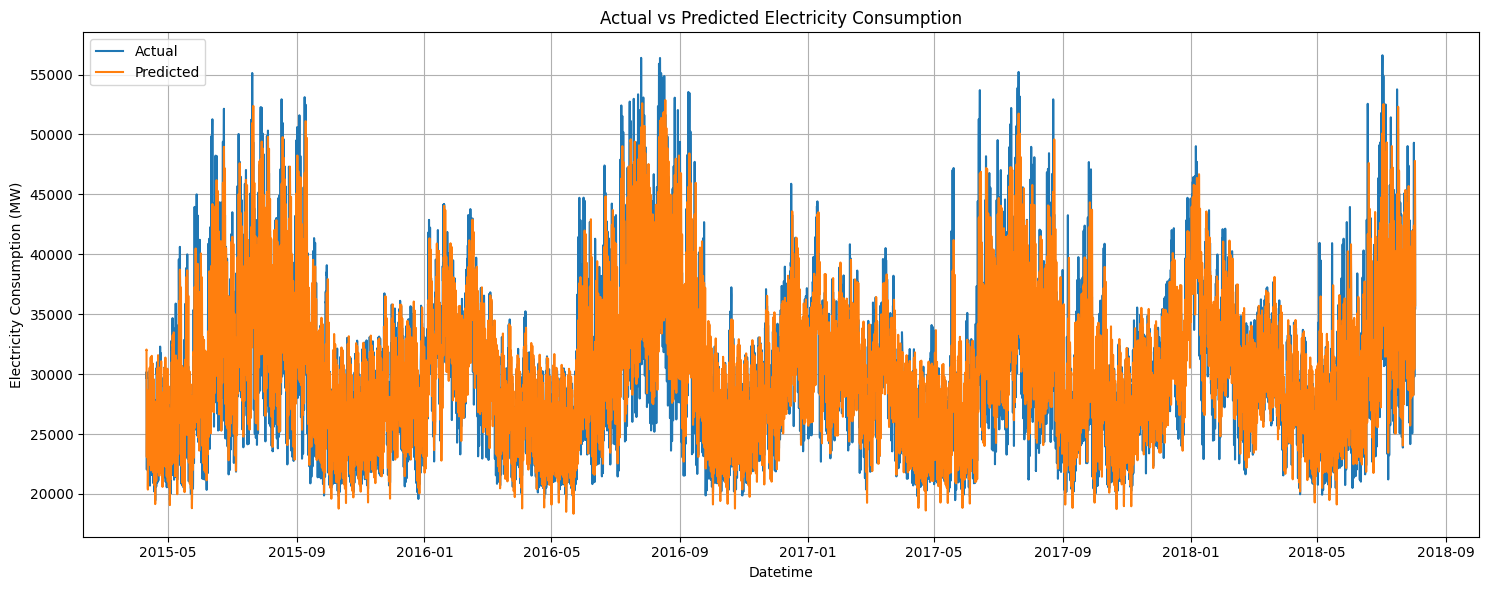

In [42]:
# Extract test dates
test_dates = pd.to_datetime(test_df['Datetime'])

print_txt('Actual vs Predicted Consumption')

plt.figure(figsize=(15, 6))

plt.plot(test_dates, y_test, label='Actual')
plt.plot(test_dates, y_pred, label='Predicted')

plt.title('Actual vs Predicted Electricity Consumption')
plt.xlabel('Datetime')
plt.ylabel('Electricity Consumption (MW)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [43]:
residuals = y_test - y_pred

Residuals Over Time


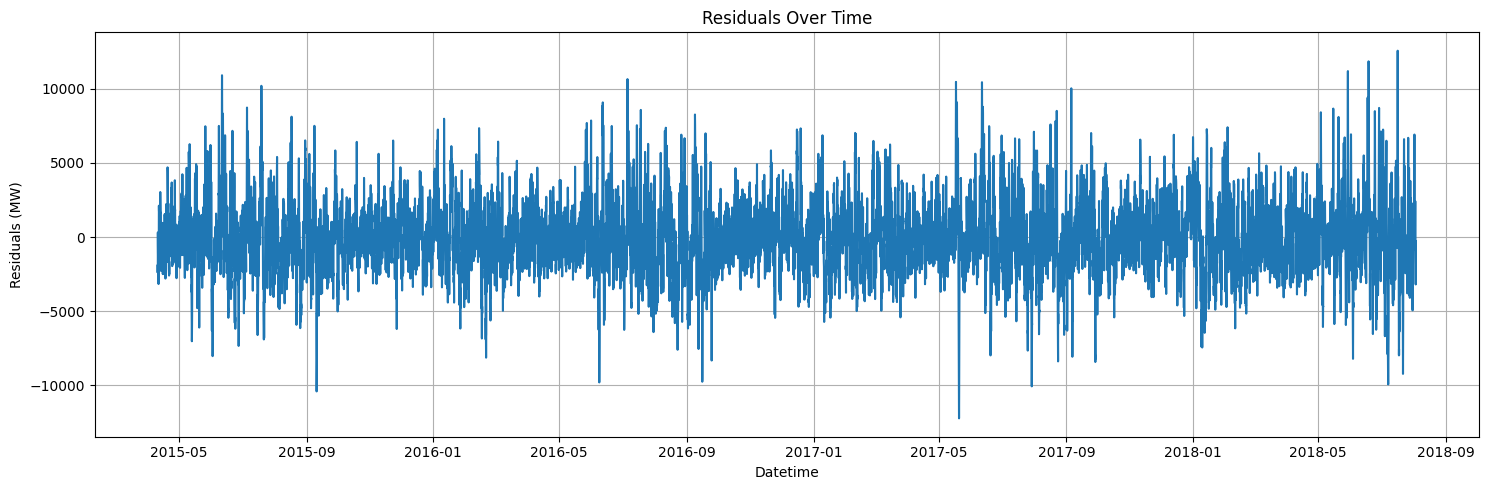

In [44]:
print_txt('Residuals Over Time')

plt.figure(figsize=(15, 5))

plt.plot(test_dates, residuals)
plt.title('Residuals Over Time')
plt.xlabel('Datetime')
plt.ylabel('Residuals (MW)')
plt.grid(True)
plt.tight_layout()
plt.show()

Residual Distribution


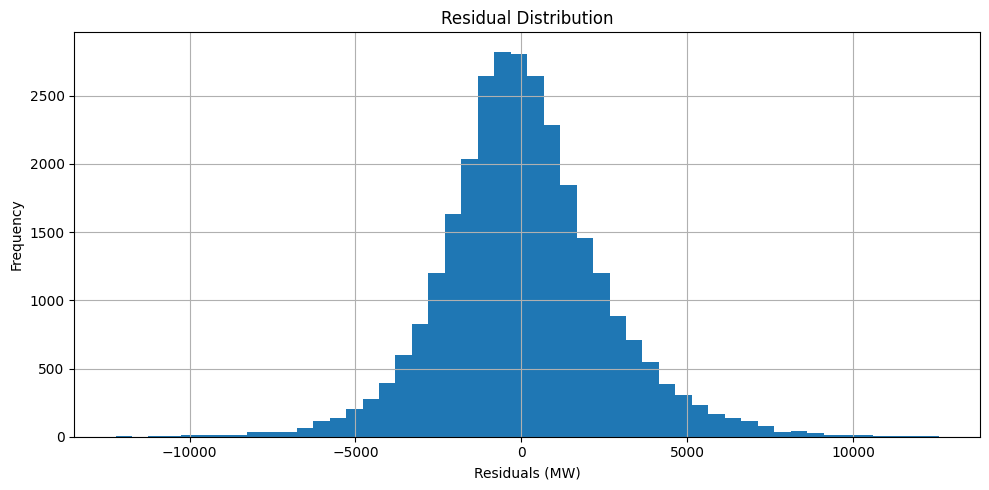

In [45]:
print_txt('Residual Distribution')

plt.figure(figsize=(10, 5))

plt.hist(residuals, bins=50)
plt.title('Residual Distribution')
plt.xlabel('Residuals (MW)')
plt.ylabel('Frequency')
plt.grid(True)
plt.tight_layout()
plt.show()